In [45]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
loan = 1_000_000
periods = 300  # (=25 years)
nom_yearly_interest = 0.0525

In [34]:
def mortgage_payment(nominal_annual_rate, loan, months, monthly_fee=0, numberformat="5.2f"):
    if not all(math.isfinite(x) for x in (nominal_annual_rate, loan, monthly_fee)):
        raise ValueError("Inputs must be finite.")
    if nominal_annual_rate < 0 or loan <= 0 or monthly_fee < 0:
        raise ValueError("Loan must be positive; rate and fee must be nonnegative.")
    if not isinstance(months, int) or isinstance(months, bool) or months <= 0:
        raise ValueError("Months must be a positive integer.")

    rate = nominal_annual_rate / 12
    if rate == 0:
        annuity = loan / months
    else:
        annuity = loan * rate / -math.expm1(-months * math.log1p(rate))

    interest = loan * rate
    principal = annuity - interest
    total = annuity + monthly_fee

    # Find the monthly rate that discounts all payments to the loan amount.
    low, high = 0.0, total / loan
    for _ in range(100):
        mid = (low + high) / 2
        if mid == 0:
            break
        present_value = total * -math.expm1(-months * math.log1p(mid)) / mid
        if present_value > loan:
            low = mid
        else:
            high = mid

    effective_annual_rate = math.expm1(12 * math.log1p((low + high) / 2))

    print(f"Totaal:    kr {total:{numberformat}}")
    print(f"Rente:     kr {interest:{numberformat}}")
    print(f"Aflossing: kr {principal:{numberformat}}")
    print(f"Effectieve Jaarlijkse Rente: {100*effective_annual_rate:.2f}% (nominaal: {100*nominal_annual_rate:.2f}%)")

In [36]:
mortgage_payment(nom_yearly_interest, loan, periods, monthly_fee=50)

Totaal:    kr 43992.22
Rente:     kr 32184.53
Aflossing: kr 11757.69
Effectieve Jaarlijkse Rente: 5.39% (nominaal: 5.25%)


In [32]:
def mortgage_payment_differences(annual_rates, loan, months, monthly_fee=0):
    rates = list(annual_rates)
    if not rates:
        raise ValueError("Provide at least one interest rate.")
    if not all(math.isfinite(rate) and rate >= 0 for rate in rates):
        raise ValueError("Interest rates must be finite and nonnegative.")
    if not math.isfinite(loan) or loan <= 0:
        raise ValueError("Loan must be finite and positive.")
    if not math.isfinite(monthly_fee) or monthly_fee < 0:
        raise ValueError("Monthly fee must be finite and nonnegative.")
    if not isinstance(months, int) or isinstance(months, bool) or months <= 0:
        raise ValueError("Months must be a positive integer.")

    def monthly_payment(annual_rate):
        rate = annual_rate / 12
        if rate == 0:
            return loan / months + monthly_fee
        annuity = loan * rate / -math.expm1(-months * math.log1p(rate))
        return annuity + monthly_fee

    reference_payment = monthly_payment(rates[0])
    return [
        (rate, monthly_payment(rate) - reference_payment)
        for rate in rates[0:]
    ]

In [37]:
mortgage_payment_differences(np.arange(0.054, 0.0495, -0.0005), loan, periods, monthly_fee=50)

[(np.float64(0.054), np.float64(0.0)),
 (np.float64(0.0535), np.float64(-218.71678174693807)),
 (np.float64(0.053), np.float64(-436.89884349178465)),
 (np.float64(0.0525), np.float64(-654.5444159801482)),
 (np.float64(0.052), np.float64(-871.651739334513)),
 (np.float64(0.0515), np.float64(-1088.2190632145648)),
 (np.float64(0.051), np.float64(-1304.2446469772476)),
 (np.float64(0.050499999999999996), np.float64(-1519.7267598366743)),
 (np.float64(0.049999999999999996), np.float64(-1734.6636810237615))]

In [39]:
def mortgage_payment_schedule(annual_rate, loan, months, monthly_fee=0):
    if not all(math.isfinite(x) for x in (annual_rate, loan, monthly_fee)):
        raise ValueError("Inputs must be finite.")
    if annual_rate < 0 or loan <= 0 or monthly_fee < 0:
        raise ValueError("Loan must be positive; rate and fee must be nonnegative.")
    if not isinstance(months, int) or isinstance(months, bool) or months <= 0:
        raise ValueError("Months must be a positive integer.")

    rate = annual_rate / 12
    if rate == 0:
        payment = loan / months
    else:
        payment = loan * rate / -math.expm1(-months * math.log1p(rate))

    remaining_loan = loan
    cumulative_costs = 0.0
    balances = []
    costs = []

    for _ in range(months):
        interest = remaining_loan * rate
        principal = min(payment, remaining_loan + interest)
        remaining_loan = max(0.0, remaining_loan - (principal - interest))
        cumulative_costs += interest + monthly_fee

        balances.append(remaining_loan)
        costs.append(cumulative_costs)

        if remaining_loan == 0:
            break

    return np.array(balances), np.array(costs)

In [41]:
smn1 = mortgage_payment_schedule(0.054, loan, periods, monthly_fee=0)
nordea = mortgage_payment_schedule(nom_yearly_interest, loan, periods, monthly_fee=0)

In [50]:
nordea[1].max()-smn1[1].max()

np.float64(-197672.41362602264)

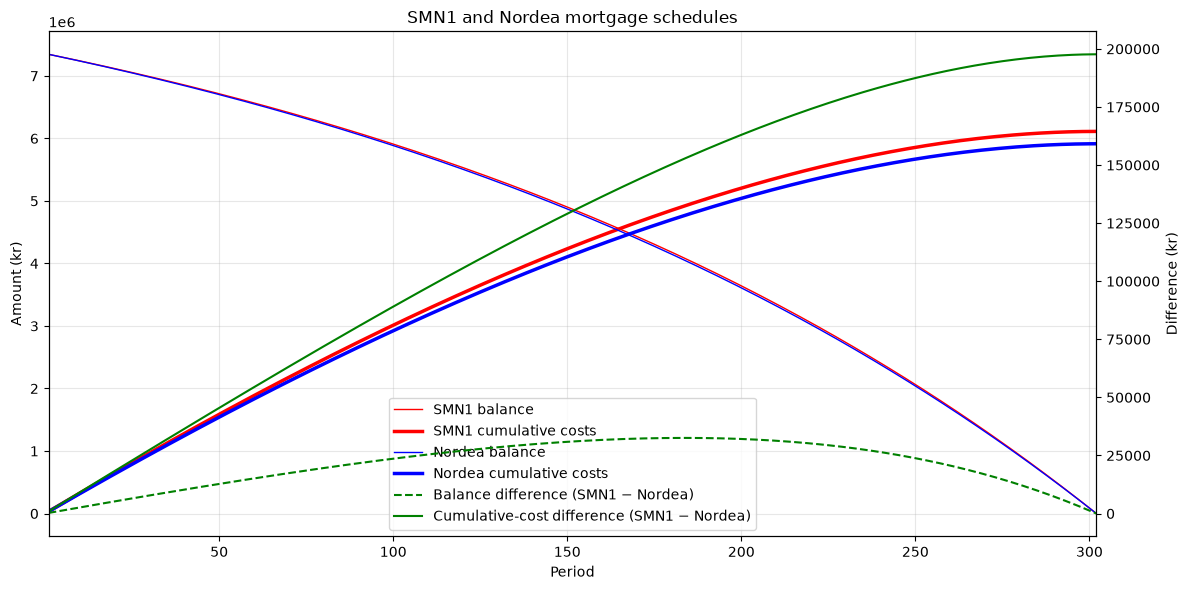

In [46]:
x = np.arange(1, periods + 1)

fig, ax = plt.subplots(figsize=(12, 6))

# Balances and cumulative costs
ax.plot(x, smn1[0], color="red", linewidth=1, label="SMN1 balance")
ax.plot(x, smn1[1], color="red", linewidth=2.5, label="SMN1 cumulative costs")
ax.plot(x, nordea[0], color="blue", linewidth=1, label="Nordea balance")
ax.plot(x, nordea[1], color="blue", linewidth=2.5, label="Nordea cumulative costs")

# Differences use a secondary axis so they remain visible
ax_diff = ax.twinx()
ax_diff.plot(x, smn1[0] - nordea[0], color="green", linestyle="--",
             label="Balance difference (SMN1 − Nordea)")
ax_diff.plot(x, smn1[1] - nordea[1], color="green", linestyle="-",
             label="Cumulative-cost difference (SMN1 − Nordea)")

ax.set(xlabel="Period", ylabel="Amount (kr)", xlim=(1, periods))
ax_diff.set_ylabel("Difference (kr)")
ax.set_title("SMN1 and Nordea mortgage schedules")
ax.grid(True, alpha=0.3)

lines, labels = ax.get_legend_handles_labels()
diff_lines, diff_labels = ax_diff.get_legend_handles_labels()
ax.legend(lines + diff_lines, labels + diff_labels, loc="best")

plt.tight_layout()
plt.show()